In [1]:
import re                              # Regular expressions: split news text into tokens
from collections import Counter         # Count how frequently each token appears

import pandas as pd                     # Store experiment results as tables
from datasets import load_dataset       # Download AG News from Hugging Face
import matplotlib.pyplot as plt         # Draw learning curves

import torch                            # PyTorch core: tensors and automatic gradients
import torch.nn as nn                   # Neural network layers and loss functions
from torch.nn.utils.rnn import pack_padded_sequence, pad_sequence
# pack_padded_sequence: let LSTM ignore padding; pad_sequence: make equal-length batches
from torch.utils.data import DataLoader, Dataset, random_split
# Dataset represents individual articles; DataLoader groups them into batches


c:\Users\William\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Text Processing — Tokenize text and build vocabulary [Person 6: No need to run]

In [2]:
# Reserve two special integer IDs: padding (0) and unknown word (1).
PAD, UNK = "<pad>", "<unk>"
PAD_IDX, UNK_IDX = 0, 1


def tokenize(text: str):
    """Turn a news article into lowercase word and punctuation tokens."""
    return re.findall(r"[a-z0-9]+(?:'[a-z]+)?|[^\sa-z0-9]", text.lower())


def build_vocab(texts, min_freq=5, max_size=30_000):
    """Create a mapping between frequently used words and their integer IDs."""
    counter = Counter()
    for t in texts:
        counter.update(tokenize(t))  # Count word frequency across the input articles.

    itos = [PAD, UNK]  # Index-to-string list; index 0 is PAD, 1 is UNK.
    for word, freq in counter.most_common(max_size):
        if freq < min_freq:  # Skip words that are too rare.
            break
        itos.append(word)

    stoi = {w: i for i, w in enumerate(itos)}  # String-to-index dictionary.
    return stoi, itos


def encode(text, stoi, max_len):
    """Convert text to token IDs and truncate to max_len tokens."""
    ids = [stoi.get(tok, UNK_IDX) for tok in tokenize(text)][:max_len]
    return ids if ids else [UNK_IDX]  # Avoid empty sequences, which LSTM cannot pack.

# Tiny example only. These mappings will be rebuilt using all AG News train text later.
example = "Wall St. Bears Claw Back Into the Black (Reuters)"
print(tokenize(example))
stoi, itos = build_vocab([example], min_freq=1)
print(stoi)
print(encode(example, stoi, max_len=10))


['wall', 'st', '.', 'bears', 'claw', 'back', 'into', 'the', 'black', '(', 'reuters', ')']
{'<pad>': 0, '<unk>': 1, 'wall': 2, 'st': 3, '.': 4, 'bears': 5, 'claw': 6, 'back': 7, 'into': 8, 'the': 9, 'black': 10, '(': 11, 'reuters': 12, ')': 13}
[2, 3, 4, 5, 6, 7, 8, 9, 10, 11]


# AG News Dataset — Data source and class definitions [Person 6: No need to run]

AG is a collection of more than 1 million news articles. The AG's news topic classification dataset is constructed by choosing 4 largest classes from the original corpus. Each class contains 30,000 training samples and 1,900 testing samples. The total number of training samples is 120,000 and testing 7,600.

See details here: https://www.kaggle.com/datasets/amananandrai/ag-news-classification-dataset?select=test.csv

Class Index:
1-World, 2-Sports, 3-Business, 4-Sci/Tech

In [3]:
# Class IDs are 0 to 3. The Linear layer must return one logit for each class.
CLASSES = ["World", "Sports", "Business", "Sci/Tech"]


In [4]:
# Load original AG News splits: train (120,000) and test (7,600).
raw = load_dataset("aRWA787/ag_news_dataset")
print(raw["train"][0])

# Build the token-ID dictionary once, so the same vocabulary is used for all data.
# Note: this uses the full original train split, before train/validation splitting.
stoi, itos = build_vocab(raw["train"]["text"])
print("Vocab size:", len(itos))  # Number of IDs available to the Embedding layer.


{'text': "wall st. bears claw back into the black (reuters) reuters - short-sellers, wall street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2, 'label_name': 'Business', 'length': 144}
Vocab size: 28384


## Prepare Training, Validation, and Test Data [Person 6: No need to run]

Build the training and test sets by encoding the text.

- Only read MAX_LEN tokens from each article.
    - The longer the sequence, the harder it is for the a vanilla RNN to learn from early tokens due to vanishing gradients. So, shorter MAX_LEN trains better (and faster).
    - AG News articles are a headline + short description, so most of the topic signal is in the first 30 or so tokens.

In [5]:
MAX_LEN = 48        # Maximum tokens per article after truncation, NOT number of articles.
BATCH_SIZE = 128    # Maximum articles in one mini-batch (one optimizer update).
SEED = 8567         # Random seed for repeatable train/validation split.

class NewsDataset(Dataset):
    def __init__(self, hf_split, stoi, max_len):
        self.labels = list(hf_split["label"])  # One class ID (0..3) per article.
        self.data = [encode(t, stoi, max_len) for t in hf_split["text"]]
        # self.data contains variable-length token-ID lists, each with <= MAX_LEN elements.

    def __len__(self):
        return len(self.labels)  # Total number of articles.

    def __getitem__(self, i):
        return self.data[i], self.labels[i]  # Return (token IDs, true class ID).


def collate(batch):
    """Pad articles in one batch and return their true sequence lengths."""
    seqs, labels = zip(*batch)  # Lists of token IDs and labels from B articles.
    lengths = torch.tensor([len(s) for s in seqs], dtype=torch.long)  # (B,)
    padded = pad_sequence(
        [torch.tensor(s, dtype=torch.long) for s in seqs],
        batch_first=True,          # Output shape: (B, T) rather than (T, B).
        padding_value=PAD_IDX,    # Shorter articles get 0s on the RIGHT.
    )
    # B = number of articles (usually 128); T = longest length in THIS batch (<= 48).
    return padded, lengths, torch.tensor(labels, dtype=torch.long)
    # Shapes: tokens (B, T), lengths (B,), labels (B,).

# Prepare integer sequences once. No extra preprocessing needed in Part 5.
full_train = NewsDataset(raw["train"], stoi, MAX_LEN)
test_ds = NewsDataset(raw["test"], stoi, MAX_LEN)

# Reserve 10% of the original 120,000 training rows for validation.
n_val = int(0.1 * len(full_train))
train_ds, val_ds = random_split(
    full_train,
    [len(full_train) - n_val, n_val],
    generator=torch.Generator().manual_seed(SEED),  # Fixed split indices.
)

train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
# Shuffle training articles to change the minibatch order.
val_dl = DataLoader(val_ds, batch_size=BATCH_SIZE, collate_fn=collate)
test_dl = DataLoader(test_ds, batch_size=BATCH_SIZE, collate_fn=collate)
# No shuffling is required for validation/test metrics.

print("Train:", len(train_ds), "Val:", len(val_ds), "Test:", len(test_ds))


Train: 108000 Val: 12000 Test: 7600


# Person 5 — PyTorch LSTM & Independent Hyperparameter Tuning

**Purpose:** Train an LSTM news classifier, study four hyperparameters separately, and evaluate a final model.

**How to run (Person 5):**
1. **RUN ONCE:** Run all setup cells through **Step 4B — Train Baseline**. Data processing and model definitions are shared by all experiments.
2. **RUN INDEPENDENTLY:** Choose any of **Step 5A / 5B / 5C / 5D**, change its five values if needed, then run *only that section*. You do **not** need to rerun the other sweeps.
3. **OPTIONAL:** Run **Step 6** to combine completed sweep results, **Step 7** to test 3 combinations (requires all four sweeps), and **Step 8–9** for final training and test evaluation (requires all four sweeps).
4. **After changing a sweep:** Re-run Steps 6–9 only if you want them to reflect the updated tuning results. Re-training the model is not required to view old saved outputs.

**For Person 6:** No need to run the training cells; please review the saved outputs. Saved notebook outputs contain the results; no CSV, PNG, or JSON files are created automatically.

**Method:** All sweeps use the same baseline, data subset, batch size, and epoch budget. Each sweep varies one hyperparameter while fixing the other three. The test set is not used for tuning.

## Step 1 — Check Input Tensors [Run once for setup; Person 6: No need to run]


**Four important symbols:** `B = Batch Size` (number of news articles processed together), `T = Sequence Length` (longest token sequence in the current batch), `E = Embedding Dimension` (number of features per token), and `H = Hidden Size` (number of features in the LSTM hidden state).

- `tokens` has shape **`(B, T)`**. For example, `(128, 48)` means 128 news articles, each represented by up to 48 integer token IDs. Because we use **dynamic padding**, the actual value of `T` can be smaller than 48.
- `lengths` has shape **`(B,)`**. Each entry gives the number of real tokens in an article, excluding padding.
- `labels` has shape **`(B,)`**. Each entry is the correct class ID: `0`, `1`, `2`, or `3`.
- `vocab_size` is approximately 28,000. It is **not** one of the dimensions in `(128, 48)`; it is the number of distinct token IDs that the Embedding layer can look up.

> **Why check tensor shapes?** Every neural network layer expects a specific input format. `nn.Embedding` takes integer token IDs, while `nn.LSTM` processes floating-point word vectors. This checkpoint inspects the data; it does not train the model.

In [6]:
import copy       # Save a separate copy of the best model weights.
import random     # Control Python random seed.
import time       # Measure training duration in seconds.

import numpy as np
from sklearn.metrics import f1_score

# GPU (CUDA) speeds up many tensor operations; CPU works too.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
VOCAB_SIZE = len(itos)  # Number of distinct token IDs, including PAD and UNK.
N_CLASSES = len(CLASSES)  # 4 categories: World, Sports, Business, Sci/Tech.

# Set seeds so repeated runs are more comparable (hardware may still differ).
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# next(iter(...)) retrieves ONE batch without starting model training.
x_batch, lengths_batch, y_batch = next(iter(train_dl))
print("Device:", device)
print("Vocabulary size:", VOCAB_SIZE)
print("Tokens:", tuple(x_batch.shape), "Lengths:", tuple(lengths_batch.shape),
      "Labels:", tuple(y_batch.shape))
print("Labels range:", int(y_batch.min()), "to", int(y_batch.max()))
# Expected: tokens (B, T), lengths (B,), labels (B,), B usually 128, T <= 48.


Device: cpu
Vocabulary size: 28384
Tokens: (128, 48) Lengths: (128,) Labels: (128,)
Labels range: 0 to 3


## Step 2 — Define PyTorch LSTM [Run once for setup; Person 6: No need to run]


**Tensor shapes from input to output:**

| Layer | Input Shape | Output Shape | Purpose |
|---|---|---|---|
| `nn.Embedding` | `(B, T)` | `(B, T, E)` | Map each integer token ID to a trainable E-dimensional vector |
| `pack_padded_sequence` | `(B, T, E)` | `PackedSequence` | Keep the LSTM from treating right-side padding as real text |
| `nn.LSTM` | `PackedSequence` | Final hidden state `(B, H)` | Learn sequential information from each article |
| `nn.Dropout` | `(B, H)` | `(B, H)` | Randomly zero out some features during training to reduce overfitting |
| `nn.Linear` | `(B, H)` | `(B, 4)` | Produce one classification score (logit) for each of the four news categories |

For example, when `B=128, T=48, E=64, H=64`, the shapes progress as follows: **`(128, 48)` → `(128, 48, 64)` → `(128, 64)` → `(128, 4)`**.

**Important:** The final dimension `4` represents the **number of categories**, not the number of neural network layers. Each row contains four **logits**, which are raw scores before Softmax. To predict a category, use `argmax(dim=1)` to choose the index of the highest logit. `CrossEntropyLoss` accepts raw logits, so **do not add Softmax manually**.

Our LSTM has **one layer and one direction**, so `hidden[-1]` contains the final hidden state for each article after its last actual token. PyTorch's built-in `nn.LSTM(dropout=...)` applies dropout between stacked LSTM layers; here, we instead apply a separate `nn.Dropout` **after** the LSTM.

In [7]:
class LSTMClassifier(nn.Module):
    # nn.Module is the base class for trainable neural networks in PyTorch.
    def __init__(self, vocab_size, embedding_dim=64, hidden_dim=64, dropout=0.2):
        super().__init__()  # Initialize the nn.Module base class.

        # Token IDs (B,T) -> word vectors (B,T,E); E = embedding_dim.
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD_IDX)

        # LSTM reads E features per token and produces H hidden features.
        # batch_first=True keeps the batch dimension first: (B,T,E).
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)

        self.dropout = nn.Dropout(dropout)  # Randomly mask features ONLY during training.
        self.fc = nn.Linear(hidden_dim, N_CLASSES)  # (B,H) -> (B,4) class scores.

    def forward(self, tokens, lengths):
        # tokens: (B,T), integers. lengths: (B,), real article lengths.
        embedded = self.embedding(tokens)  # (B,T,E), floating-point word vectors.

        # Exclude right-padding from the time steps processed by the LSTM.
        # lengths must be on CPU; unsorted batches are allowed.
        packed = pack_padded_sequence(
            embedded, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, (hidden, cell) = self.lstm(packed)
        # hidden: (1,B,H) for ONE layer, ONE direction; cell has the same shape.
        # We only need the hidden state for document classification.
        final_hidden = hidden[-1]  # (B,H): one feature vector per news article.

        logits = self.fc(self.dropout(final_hidden))  # (B,4), 4 raw class scores.
        return logits  # Raw logits, NOT probabilities (no Softmax here).

# Build the baseline network on CPU or GPU; weights are still random.
example_model = LSTMClassifier(VOCAB_SIZE).to(device)
example_model.eval()  # Disable Dropout for a stable shape-check forward pass.
with torch.no_grad():  # No gradients needed when we are only checking dimensions.
    sample_logits = example_model(x_batch.to(device), lengths_batch)
print("Model output (logits) shape:", tuple(sample_logits.shape))
# Expected: (B, 4), usually (128,4). Each article gets four category scores.


Model output (logits) shape: (128, 4)


### Step 2A — Check Forward Shapes [Optional; Person 6: No need to run]


This cell displays tensor shapes **without training** the model. `B` is the batch size (usually 128); `T` is the longest sequence in this batch (at most 48); `E=64` is the embedding dimension; `H=64` is the LSTM hidden size; and `4` is the number of AG News categories.

A tensor of shape `(B, T)` holds **token IDs**, not token probabilities. A tensor of shape `(B, 4)` holds **classification logits**, not four news articles.

In [8]:
# Inspect a single batch. This does NOT train the network.
B, T = x_batch.shape  # B: articles in this batch; T: padded sequence length.
example_model.eval()
with torch.no_grad():
    word_vectors = example_model.embedding(x_batch.to(device))  # (B,T,E)
    output_scores = example_model(x_batch.to(device), lengths_batch)  # (B,4)
    predicted_class = output_scores.argmax(dim=1)  # (B,)

print(f"Input tokens: {tuple(x_batch.shape)} = (B={B}, T={T})")
print("Embedding vectors:", tuple(word_vectors.shape), "= (B,T,E)")
print("Output logits:", tuple(output_scores.shape), "= (B,4)")
print("Predicted labels:", tuple(predicted_class.shape), "= (B,)")
print("First news item logits:", output_scores[0].cpu().tolist())
print("First predicted class:", CLASSES[predicted_class[0].item()])


Input tokens: (128, 48) = (B=128, T=48)
Embedding vectors: (128, 48, 64) = (B,T,E)
Output logits: (128, 4) = (B,4)
Predicted labels: (128,) = (B,)
First news item logits: [0.10080906748771667, -0.05989662930369377, 0.17848701775074005, 0.12779919803142548]
First predicted class: Business


## Step 3 — Training and Validation Functions [Run once for setup; Person 6: No need to run]


**Training loop for each mini-batch:**

1. `model(tokens, lengths)`: Perform **forward propagation** and produce logits with shape `(B, 4)`.
2. `loss = CrossEntropyLoss(logits, labels)`: Compare the logits against the true class IDs with shape `(B,)` and calculate a **scalar loss** (shape `()`).
3. `optimizer.zero_grad()`: Clear gradients from the previous batch. Otherwise, PyTorch would **accumulate** gradients by default.
4. `loss.backward()`: Use **autograd / backpropagation** to calculate gradients for every trainable parameter.
5. `optimizer.step()`: Let the Adam optimizer update model weights using those gradients and the learning rate.

**Validation** uses `model.eval()` and disables gradient tracking. It calculates metrics but **does not update** weights. `argmax(dim=1)` converts logits of shape `(B, 4)` into predicted class IDs of shape `(B,)`.

In general, a lower **loss** indicates a better fit to the true categories; **accuracy** is the fraction of correctly classified articles; **macro-F1** averages the per-class F1 scores. `training_time_s` measures training steps only, while `total_fit_time_s` includes both training and validation.

In [9]:
def run_epoch(model, loader, criterion, optimizer=None):
    # optimizer=None means evaluation/validation; otherwise train the model.
    is_training = optimizer is not None
    model.train() if is_training else model.eval()
    # train() turns Dropout ON; eval() turns Dropout OFF.

    total_loss = 0.0
    total_correct = 0
    total_samples = 0
    all_labels, all_preds = [], []  # Needed for macro-F1 and confusion matrix.

    with torch.set_grad_enabled(is_training):  # No gradient graph during evaluation.
        for tokens, lengths, labels in loader:  # One batch at a time.
            tokens = tokens.to(device)  # (B,T), send input IDs to CPU/GPU.
            labels = labels.to(device)  # (B,), true category IDs.
            logits = model(tokens, lengths)  # Forward: (B,T) -> (B,4).
            loss = criterion(logits, labels)  # One scalar cross-entropy loss.

            if is_training:
                optimizer.zero_grad()  # Reset old gradients (PyTorch accumulates by default).
                loss.backward()        # Backpropagation: compute dLoss/dWeights.
                optimizer.step()       # Adam: update weights using gradients.

            predictions = logits.argmax(dim=1)  # (B,4) -> (B,), predicted class IDs.
            n = labels.size(0)                  # Actual batch size (last batch may be smaller).
            total_loss += loss.item() * n       # Weight mean batch loss by batch size.
            total_correct += (predictions == labels).sum().item()
            total_samples += n
            all_labels.extend(labels.cpu().tolist())
            all_preds.extend(predictions.cpu().tolist())

    return {
        "loss": total_loss / total_samples,          # Mean loss per article.
        "accuracy": total_correct / total_samples,  # Proportion correct, from 0 to 1.
        "macro_f1": f1_score(all_labels, all_preds, labels=list(range(N_CLASSES)),
                             average="macro", zero_division=0),
        "labels": all_labels,
        "predictions": all_preds,
    }


def sync_gpu():
    # CUDA operations can be asynchronous; synchronize before timing on GPU.
    if device.type == "cuda":
        torch.cuda.synchronize()


def make_train_loader(dataset):
    # shuffle=True changes training batch order; fixed seed aids comparisons.
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True,
                      collate_fn=collate, generator=torch.Generator().manual_seed(SEED))


def make_eval_loader(dataset):
    # No shuffle needed for validation/test; do not update their labels.
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate)


def train_model(config, train_dataset, val_dataset, epochs=3, verbose=True):
    # Set same random seed at the start of each tuning run.
    torch.manual_seed(SEED)
    if device.type == "cuda":
        torch.cuda.manual_seed_all(SEED)

    # config is a dictionary: embedding_dim, hidden_dim, dropout, learning_rate.
    model = LSTMClassifier(
        VOCAB_SIZE, config["embedding_dim"], config["hidden_dim"], config["dropout"]
    ).to(device)
    criterion = nn.CrossEntropyLoss()  # Multiclass classification objective.
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
    train_loader = make_train_loader(train_dataset)
    validation_loader = make_eval_loader(val_dataset)

    history = []                 # Store learning curve points for every epoch.
    best_val_acc = -1.0          # Every valid accuracy >= 0 beats this.
    best_val_loss = float("inf") # Tie-breaker if two validation accuracies match.
    best_state = None            # Best checkpoint (a COPY of model weights).
    best_epoch = None
    training_time_s = 0.0
    sync_gpu()
    full_start = time.perf_counter()  # Total time includes train + validation.

    for epoch in range(1, epochs + 1):
        sync_gpu()
        epoch_start = time.perf_counter()
        train_metrics = run_epoch(model, train_loader, criterion, optimizer)
        sync_gpu()
        epoch_train_s = time.perf_counter() - epoch_start
        training_time_s += epoch_train_s

        # Validation is always performed without an optimizer (no updates).
        val_metrics = run_epoch(model, validation_loader, criterion)
        row = {
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_loss": val_metrics["loss"],
            "val_accuracy": val_metrics["accuracy"],
            "val_macro_f1": val_metrics["macro_f1"],
            "accuracy_gap": train_metrics["accuracy"] - val_metrics["accuracy"],
            "epoch_train_time_s": epoch_train_s,
        }
        history.append(row)

        # Select only by VALIDATION data; never choose weights using Test Accuracy.
        improved = (row["val_accuracy"] > best_val_acc or
                    (row["val_accuracy"] == best_val_acc and row["val_loss"] < best_val_loss))
        if improved:
            best_val_acc = row["val_accuracy"]
            best_val_loss = row["val_loss"]
            best_state = copy.deepcopy(model.state_dict())  # Save independent best weights.
            best_epoch = epoch

        if verbose:
            print(f"Epoch {epoch}/{epochs} | "
                  f"train acc {row['train_accuracy']:.3f}, "
                  f"val acc {row['val_accuracy']:.3f}, "
                  f"train loss {row['train_loss']:.3f}, "
                  f"val loss {row['val_loss']:.3f}")

    sync_gpu()
    total_fit_time_s = time.perf_counter() - full_start
    model.load_state_dict(best_state)  # Restore validation-best weights for later use.
    history_df = pd.DataFrame(history)
    best_row = history_df.loc[history_df["epoch"] == best_epoch].iloc[0].to_dict()

    return model, history_df, best_row, {
        "best_epoch": best_epoch,
        "training_time_s": training_time_s,
        "total_fit_time_s": total_fit_time_s,
        "parameters": sum(p.numel() for p in model.parameters()),  # Model parameter count.
    }


## Step 4 — Shared Tuning Setup [Run once for setup; Person 6: No need to run]

**Purpose:** Define the same tuning subset, baseline values, and reusable training/plot functions for all four independent sweeps.

- **Train:** 20,000 articles. **Validation:** 4,000 articles. **Tuning:** 5 epochs per model.
- Fixed random seed and data split keep experiments more comparable.
- The baseline is `E=64`, `H=64`, `Dropout=0.2`, `LR=0.001`.
- **Run this setup once after Steps 1–3.** Rerunning the setup clears the in-memory sweep results. It does not itself train a model.

In [10]:
from torch.utils.data import Subset

# Shared settings for every sweep
TUNE_TRAIN_SIZE = min(20_000, len(train_ds))
TUNE_VAL_SIZE = min(4_000, len(val_ds))
TUNE_EPOCHS = 5

# Select fixed subsets once. All parameter values use the SAME articles.
train_indices = torch.randperm(
    len(train_ds), generator=torch.Generator().manual_seed(SEED + 1)
)[:TUNE_TRAIN_SIZE].tolist()
val_indices = torch.randperm(
    len(val_ds), generator=torch.Generator().manual_seed(SEED + 2)
)[:TUNE_VAL_SIZE].tolist()
tune_train_ds = Subset(train_ds, train_indices)
tune_val_ds = Subset(val_ds, val_indices)

BASELINE = {
    "embedding_dim": 64,
    "hidden_dim": 64,
    "dropout": 0.2,
    "learning_rate": 0.001,
}

PARAMETER_LABELS = {
    "embedding_dim": "Embedding Dimension",
    "hidden_dim": "LSTM Hidden Size",
    "dropout": "Dropout Rate",
    "learning_rate": "Learning Rate",
}

# Store results from each independent tuning section.
sweep_results = {}
sweep_histories = {}

print(f"Tuning subset: {len(tune_train_ds)} train / {len(tune_val_ds)} validation")
print("Epochs per model:", TUNE_EPOCHS)

# Optional downstream results start empty until their steps are run.
combination_results = None
final_model = None


Tuning subset: 20000 train / 4000 validation
Epochs per model: 5


### Step 4A — Define the Reusable Sweep Function [Run once for setup; Person 6: No need to run]

**Purpose:** Train the non-baseline values of one selected parameter, record validation metrics, and draw a standard trend plot. Each Step 5 section calls this function independently.

The shared baseline is trained in Step 4B, so it does not need to be trained four times.

In [11]:
def run_sweep(parameter, values):
    """Test five values of ONE parameter while keeping the others fixed."""
    # Include the baseline result already trained in Step 4B.
    assert parameter in BASELINE
    assert len(values) == 5 and len(set(values)) == 5
    assert any(np.isclose(v, BASELINE[parameter]) for v in values), "Include the baseline value."

    rows = [baseline_result.copy()]
    histories = [baseline_history.assign(configuration="Baseline")]

    for value in values:
        if np.isclose(value, BASELINE[parameter]):
            continue  # Reuse the baseline instead of training it again.

        config = BASELINE.copy()
        config[parameter] = int(value) if parameter in ("embedding_dim", "hidden_dim") else float(value)
        config["name"] = f"{PARAMETER_LABELS[parameter]} = {value:g}"

        print(f"\nTraining {config['name']}")
        model, history, best, info = train_model(
            config, tune_train_ds, tune_val_ds, epochs=TUNE_EPOCHS
        )
        rows.append({
            **config,
            "best_epoch": info["best_epoch"],
            "train_accuracy": best["train_accuracy"],
            "val_accuracy": best["val_accuracy"],
            "train_loss": best["train_loss"],
            "val_loss": best["val_loss"],
            "training_time_s": info["training_time_s"],
        })
        histories.append(history.assign(configuration=config["name"]))
        del model  # Keep metrics, not all trained models.

    result = pd.DataFrame(rows).sort_values(parameter).reset_index(drop=True)
    history_result = pd.concat(histories, ignore_index=True)
    return result, history_result


def plot_sweep(parameter, values, result):
    """Plot best validation accuracy for the five tested parameter values."""
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(result[parameter], result["val_accuracy"] * 100, marker="o")
    ax.axvline(BASELINE[parameter], linestyle="--", color="gray", label="Baseline")

    # Multiplicative x-axis spacing for dimensions and learning rate.
    if parameter in ("embedding_dim", "hidden_dim"):
        ax.set_xscale("log", base=2)
    elif parameter == "learning_rate":
        ax.set_xscale("log")

    ax.set_xticks(values)
    ax.set_xticklabels([f"{v:g}" for v in values])
    ax.set(title=PARAMETER_LABELS[parameter] + " Tuning",
           xlabel=PARAMETER_LABELS[parameter], ylabel="Best Validation Accuracy (%)")
    ax.grid(alpha=0.2)
    ax.legend()
    plt.tight_layout()
    plt.show()

### Step 4B — Train Shared Baseline [Run once for setup; Person 6: No need to run]

**Purpose:** Obtain a single baseline result reused by all four independent tuning sections. This is **one model training run** (5 epochs). You only need to train it once, even when changing parameter ranges in Step 5.

In [12]:
# This is the only baseline training run. Step 5 reuses these metrics.
print("Training shared baseline...")
baseline_model, baseline_history, baseline_best, baseline_info = train_model(
    BASELINE, tune_train_ds, tune_val_ds, epochs=TUNE_EPOCHS
)
baseline_result = {
    **BASELINE,
    "name": "Baseline",
    "best_epoch": baseline_info["best_epoch"],
    "train_accuracy": baseline_best["train_accuracy"],
    "val_accuracy": baseline_best["val_accuracy"],
    "train_loss": baseline_best["train_loss"],
    "val_loss": baseline_best["val_loss"],
    "training_time_s": baseline_info["training_time_s"],
}
del baseline_model
print(f"Baseline best Validation Accuracy: {baseline_result['val_accuracy'] * 100:.2f}%")

Training shared baseline...
Epoch 1/5 | train acc 0.388, val acc 0.568, train loss 1.262, val loss 0.981
Epoch 2/5 | train acc 0.668, val acc 0.737, train loss 0.802, val loss 0.679
Epoch 3/5 | train acc 0.798, val acc 0.792, train loss 0.553, val loss 0.574
Epoch 4/5 | train acc 0.855, val acc 0.805, train loss 0.418, val loss 0.533
Epoch 5/5 | train acc 0.888, val acc 0.840, train loss 0.338, val loss 0.478
Baseline best Validation Accuracy: 83.97%


## Step 5A — Embedding Dimension Tuning [Run independently; Person 6: No need to run]

**Purpose:** How does the dimensionality of each word embedding affect classification?

**To change this experiment:** Edit only `EMBEDDING_VALUES` in the next cell, then run that cell again. You do not need to run Steps 5A–5D in order or rerun other sweeps. All other hyperparameters stay at the same baseline settings.

**Person 6:** No need to run this section; the saved table and plot can be reviewed directly.


Training Embedding Dimension = 16
Epoch 1/5 | train acc 0.332, val acc 0.444, train loss 1.342, val loss 1.201
Epoch 2/5 | train acc 0.527, val acc 0.588, train loss 1.065, val loss 0.921
Epoch 3/5 | train acc 0.640, val acc 0.656, train loss 0.831, val loss 0.784
Epoch 4/5 | train acc 0.708, val acc 0.718, train loss 0.698, val loss 0.688
Epoch 5/5 | train acc 0.767, val acc 0.763, train loss 0.596, val loss 0.610

Training Embedding Dimension = 32
Epoch 1/5 | train acc 0.357, val acc 0.485, train loss 1.302, val loss 1.116
Epoch 2/5 | train acc 0.585, val acc 0.682, train loss 0.959, val loss 0.807
Epoch 3/5 | train acc 0.739, val acc 0.746, train loss 0.684, val loss 0.657
Epoch 4/5 | train acc 0.807, val acc 0.776, train loss 0.537, val loss 0.592
Epoch 5/5 | train acc 0.845, val acc 0.810, train loss 0.447, val loss 0.536

Training Embedding Dimension = 128
Epoch 1/5 | train acc 0.412, val acc 0.610, train loss 1.232, val loss 0.926
Epoch 2/5 | train acc 0.711, val acc 0.783, tra

,embedding_dim,train_accuracy,val_accuracy,val_loss,best_epoch
0,16,0.76700,0.76350,0.610322,5
1,32,0.84470,0.81050,0.535588,5
2,64,0.88755,0.83975,0.477566,5
3,128,0.91355,0.85150,0.478309,5
4,256,0.93980,0.85900,0.488333,5


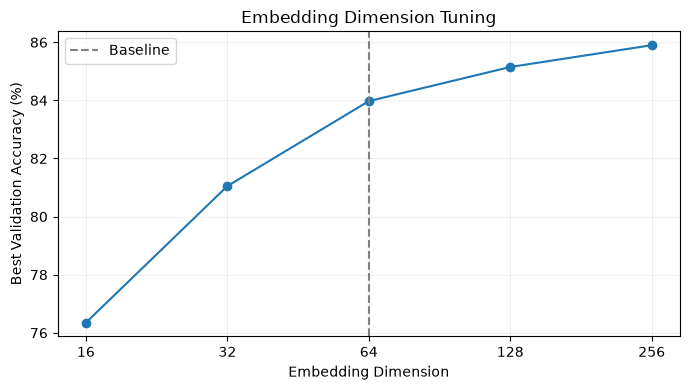

In [13]:
# Five values to test; change this list to rerun only this section.
EMBEDDING_VALUES = [16, 32, 64, 128, 256]

# Train four non-baseline models, reusing the shared baseline result.
sweep_results["embedding_dim"], sweep_histories["embedding_dim"] = run_sweep(
    "embedding_dim", EMBEDDING_VALUES
)

# Updated tuning results invalidate any previously fitted combination/final model.
combination_results = None
final_model = None

# Display a small results table and a standard accuracy trend plot.
display(sweep_results["embedding_dim"][["embedding_dim", "train_accuracy", "val_accuracy", "val_loss", "best_epoch"]])
plot_sweep("embedding_dim", EMBEDDING_VALUES, sweep_results["embedding_dim"])

## Step 5B — LSTM Hidden Size Tuning [Run independently; Person 6: No need to run]

**Purpose:** How does LSTM model capacity affect classification?

**To change this experiment:** Edit only `HIDDEN_VALUES` in the next cell, then run that cell again. You do not need to run Steps 5A–5D in order or rerun other sweeps. All other hyperparameters stay at the same baseline settings.

**Person 6:** No need to run this section; the saved table and plot can be reviewed directly.


Training LSTM Hidden Size = 16
Epoch 1/5 | train acc 0.279, val acc 0.350, train loss 1.382, val loss 1.358
Epoch 2/5 | train acc 0.436, val acc 0.575, train loss 1.247, val loss 1.051
Epoch 3/5 | train acc 0.669, val acc 0.707, train loss 0.881, val loss 0.787
Epoch 4/5 | train acc 0.776, val acc 0.756, train loss 0.658, val loss 0.691
Epoch 5/5 | train acc 0.833, val acc 0.789, train loss 0.518, val loss 0.612

Training LSTM Hidden Size = 32
Epoch 1/5 | train acc 0.328, val acc 0.429, train loss 1.351, val loss 1.220
Epoch 2/5 | train acc 0.545, val acc 0.626, train loss 1.029, val loss 0.867
Epoch 3/5 | train acc 0.718, val acc 0.750, train loss 0.724, val loss 0.669
Epoch 4/5 | train acc 0.813, val acc 0.794, train loss 0.534, val loss 0.585
Epoch 5/5 | train acc 0.863, val acc 0.817, train loss 0.420, val loss 0.531

Training LSTM Hidden Size = 128
Epoch 1/5 | train acc 0.451, val acc 0.645, train loss 1.170, val loss 0.863
Epoch 2/5 | train acc 0.711, val acc 0.767, train loss 0

,hidden_dim,train_accuracy,val_accuracy,val_loss,best_epoch
0,16,0.83290,0.78925,0.612092,5
1,32,0.86270,0.81725,0.531107,5
2,64,0.88755,0.83975,0.477566,5
3,128,0.89270,0.84350,0.471311,5
4,256,0.89705,0.83650,0.473576,5


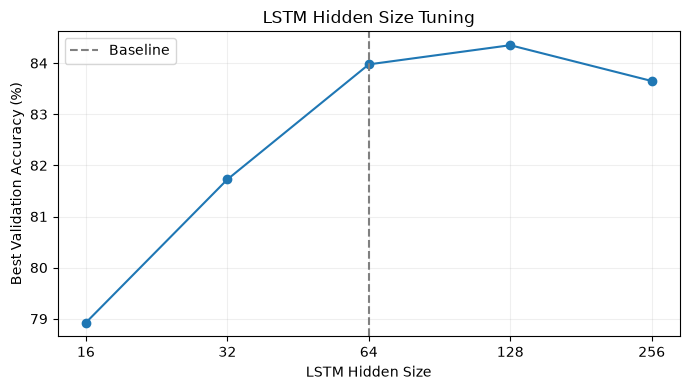

In [14]:
# Five values to test; change this list to rerun only this section.
HIDDEN_VALUES = [16, 32, 64, 128, 256]

# Train four non-baseline models, reusing the shared baseline result.
sweep_results["hidden_dim"], sweep_histories["hidden_dim"] = run_sweep(
    "hidden_dim", HIDDEN_VALUES
)

# Updated tuning results invalidate any previously fitted combination/final model.
combination_results = None
final_model = None

# Display a small results table and a standard accuracy trend plot.
display(sweep_results["hidden_dim"][["hidden_dim", "train_accuracy", "val_accuracy", "val_loss", "best_epoch"]])
plot_sweep("hidden_dim", HIDDEN_VALUES, sweep_results["hidden_dim"])

## Step 5C — Dropout Rate Tuning [Run independently; Person 6: No need to run]

**Purpose:** How does regularization affect classification and generalization?

**To change this experiment:** Edit only `DROPOUT_VALUES` in the next cell, then run that cell again. You do not need to run Steps 5A–5D in order or rerun other sweeps. All other hyperparameters stay at the same baseline settings.

**Person 6:** No need to run this section; the saved table and plot can be reviewed directly.


Training Dropout Rate = 0
Epoch 1/5 | train acc 0.403, val acc 0.591, train loss 1.237, val loss 0.941
Epoch 2/5 | train acc 0.688, val acc 0.753, train loss 0.760, val loss 0.649
Epoch 3/5 | train acc 0.808, val acc 0.802, train loss 0.523, val loss 0.557
Epoch 4/5 | train acc 0.863, val acc 0.819, train loss 0.393, val loss 0.503
Epoch 5/5 | train acc 0.895, val acc 0.841, train loss 0.314, val loss 0.471

Training Dropout Rate = 0.1
Epoch 1/5 | train acc 0.396, val acc 0.584, train loss 1.250, val loss 0.965
Epoch 2/5 | train acc 0.677, val acc 0.746, train loss 0.784, val loss 0.676
Epoch 3/5 | train acc 0.805, val acc 0.795, train loss 0.534, val loss 0.566
Epoch 4/5 | train acc 0.859, val acc 0.811, train loss 0.405, val loss 0.522
Epoch 5/5 | train acc 0.890, val acc 0.841, train loss 0.327, val loss 0.470

Training Dropout Rate = 0.4
Epoch 1/5 | train acc 0.376, val acc 0.551, train loss 1.283, val loss 1.026
Epoch 2/5 | train acc 0.650, val acc 0.718, train loss 0.834, val lo

,dropout,train_accuracy,val_accuracy,val_loss,best_epoch
0,0.0,0.89545,0.84075,0.470801,5
1,0.1,0.89005,0.84050,0.470017,5
2,0.2,0.88755,0.83975,0.477566,5
3,0.4,0.87445,0.83200,0.496237,5
4,0.6,0.86925,0.83675,0.500310,5


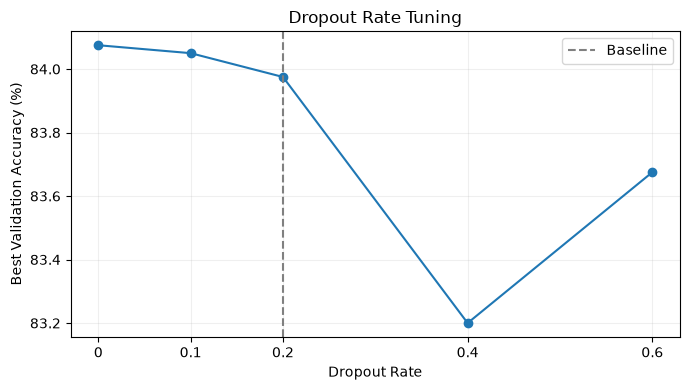

In [15]:
# Five values to test; change this list to rerun only this section.
DROPOUT_VALUES = [0.0, 0.1, 0.2, 0.4, 0.6]

# Train four non-baseline models, reusing the shared baseline result.
sweep_results["dropout"], sweep_histories["dropout"] = run_sweep(
    "dropout", DROPOUT_VALUES
)

# Updated tuning results invalidate any previously fitted combination/final model.
combination_results = None
final_model = None

# Display a small results table and a standard accuracy trend plot.
display(sweep_results["dropout"][["dropout", "train_accuracy", "val_accuracy", "val_loss", "best_epoch"]])
plot_sweep("dropout", DROPOUT_VALUES, sweep_results["dropout"])

## Step 5D — Learning Rate Tuning [Run independently; Person 6: No need to run]

**Purpose:** How does the optimizer learning rate affect convergence within five epochs?

**To change this experiment:** Edit only `LEARNING_RATE_VALUES` in the next cell, then run that cell again. You do not need to run Steps 5A–5D in order or rerun other sweeps. All other hyperparameters stay at the same baseline settings.

**Person 6:** No need to run this section; the saved table and plot can be reviewed directly.


Training Learning Rate = 0.00316228
Epoch 1/5 | train acc 0.536, val acc 0.751, train loss 1.022, val loss 0.654
Epoch 2/5 | train acc 0.823, val acc 0.828, train loss 0.501, val loss 0.495
Epoch 3/5 | train acc 0.892, val acc 0.855, train loss 0.331, val loss 0.467
Epoch 4/5 | train acc 0.926, val acc 0.859, train loss 0.241, val loss 0.461
Epoch 5/5 | train acc 0.946, val acc 0.864, train loss 0.182, val loss 0.473

Training Learning Rate = 0.01
Epoch 1/5 | train acc 0.632, val acc 0.833, train loss 0.886, val loss 0.506
Epoch 2/5 | train acc 0.882, val acc 0.865, train loss 0.368, val loss 0.423
Epoch 3/5 | train acc 0.931, val acc 0.871, train loss 0.230, val loss 0.415
Epoch 4/5 | train acc 0.956, val acc 0.869, train loss 0.149, val loss 0.460
Epoch 5/5 | train acc 0.970, val acc 0.859, train loss 0.100, val loss 0.515

Training Learning Rate = 0.0316228
Epoch 1/5 | train acc 0.692, val acc 0.835, train loss 0.781, val loss 0.503
Epoch 2/5 | train acc 0.871, val acc 0.849, train

,learning_rate,train_accuracy,val_accuracy,val_loss,best_epoch
0,0.001000,0.88755,0.83975,0.477566,5
1,0.003162,0.94615,0.86425,0.473041,5
2,0.010000,0.93095,0.87075,0.414989,3
3,0.031623,0.90500,0.86350,0.443116,3
4,0.100000,0.33200,0.33400,1.395444,2


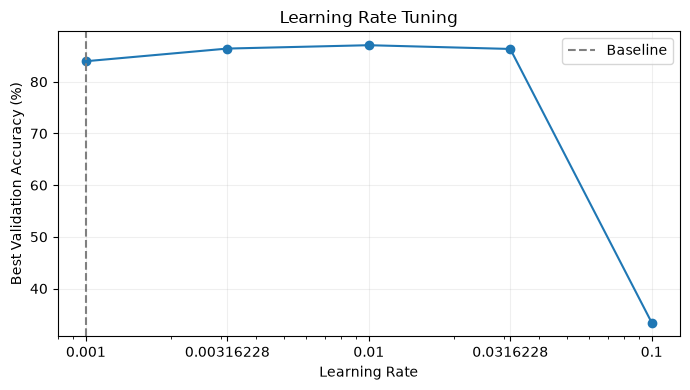

In [16]:
# Five values to test; change this list to rerun only this section.
LEARNING_RATE_VALUES = np.logspace(-3, -1, 5).tolist()

# Train four non-baseline models, reusing the shared baseline result.
sweep_results["learning_rate"], sweep_histories["learning_rate"] = run_sweep(
    "learning_rate", LEARNING_RATE_VALUES
)

# Updated tuning results invalidate any previously fitted combination/final model.
combination_results = None
final_model = None

# Display a small results table and a standard accuracy trend plot.
display(sweep_results["learning_rate"][["learning_rate", "train_accuracy", "val_accuracy", "val_loss", "best_epoch"]])
plot_sweep("learning_rate", LEARNING_RATE_VALUES, sweep_results["learning_rate"])

## Step 6 — Summarize Completed Sweeps [No training; Person 6: Can view saved results]

**Purpose:** Combine whichever of the four sweeps you have already run into one summary table. You can run this section at any time after at least one Step 5 experiment.

**Important:** If you change any Step 5 values, rerun **that** Step 5 cell and then rerun this summary. No other sweeps need to be retrained.

,Hyperparameter,Best Tested Value,Best Validation Accuracy (%)
0,Embedding Dimension,256.00,85.90
1,LSTM Hidden Size,128.00,84.35
2,Dropout Rate,0.00,84.08
3,Learning Rate,0.01,87.08


Completed sweeps: 4/4


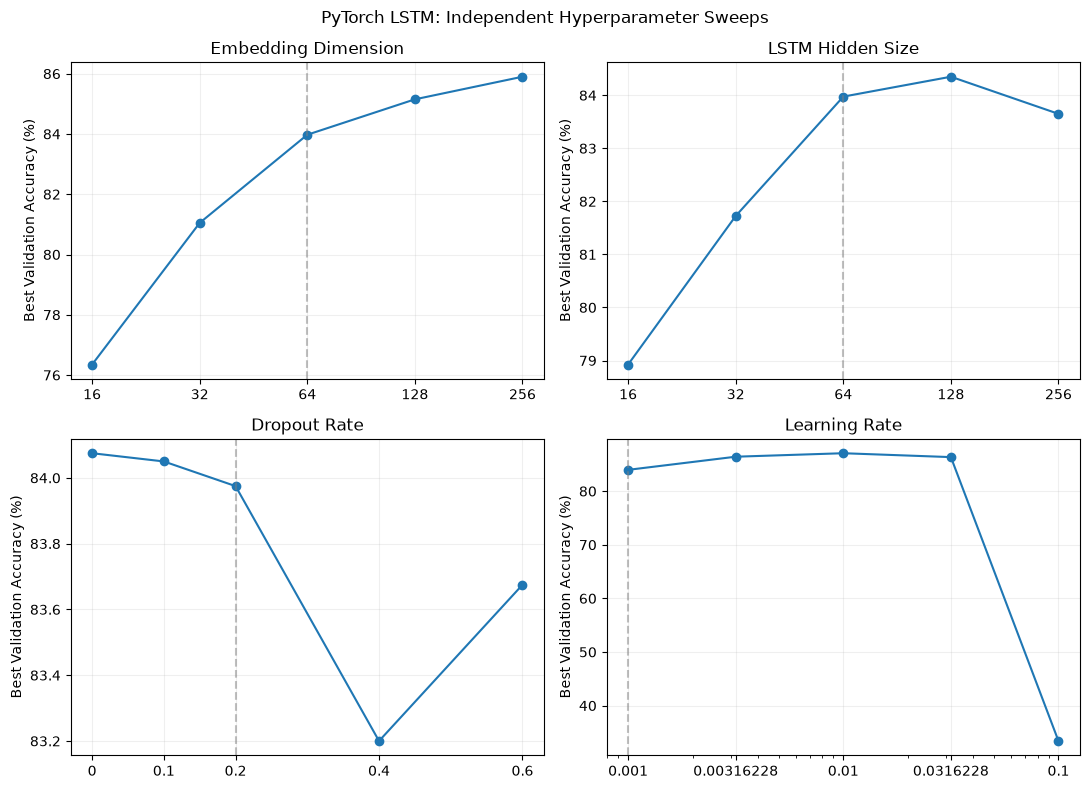

In [17]:
# Summary only: no model training occurs here.
if sweep_results:
    best_per_parameter = []
    for parameter, result in sweep_results.items():
        winner = result.sort_values(
            ["val_accuracy", "val_loss"], ascending=[False, True]
        ).iloc[0]
        best_per_parameter.append({
            "Hyperparameter": PARAMETER_LABELS[parameter],
            "Best Tested Value": winner[parameter],
            "Best Validation Accuracy (%)": round(winner["val_accuracy"] * 100, 2),
        })
    display(pd.DataFrame(best_per_parameter))
    print(f"Completed sweeps: {len(sweep_results)}/4")
else:
    print("Run any Step 5 tuning section first.")

# Optional presentation overview: four plots in one figure, without retraining.
if len(sweep_results) == 4:
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    for ax, parameter in zip(axes.flat, PARAMETER_LABELS):
        result = sweep_results[parameter]
        ax.plot(result[parameter], result["val_accuracy"] * 100, marker="o")
        ax.axvline(BASELINE[parameter], linestyle="--", color="gray", alpha=0.5)
        if parameter in ("embedding_dim", "hidden_dim"):
            ax.set_xscale("log", base=2)
        elif parameter == "learning_rate":
            ax.set_xscale("log")
        values = result[parameter].tolist()
        ax.set_xticks(values)
        ax.set_xticklabels([f"{v:g}" for v in values])
        ax.set(title=PARAMETER_LABELS[parameter], ylabel="Best Validation Accuracy (%)")
        ax.grid(alpha=0.2)
    plt.suptitle("PyTorch LSTM: Independent Hyperparameter Sweeps")
    plt.tight_layout()
    plt.show()


## Step 7 — Optional Parameter Combinations [Optional training; Person 6: No need to run]

**Purpose:** Test whether promising settings from different sweeps also work well when combined. This section trains up to **three additional models** on the tuning subset.

- First run all of Steps 5A–5D.
- **This is optional** for sensitivity plots. If you change any individual sweep, rerun this cell if you want combination results to reflect that change.
- Select combinations by Validation Accuracy; never use Test Accuracy for model selection.

In [18]:
# Optional training section; run it only after all four parameter sweeps.
required_parameters = list(PARAMETER_LABELS)
if not all(p in sweep_results for p in required_parameters):
    print("Skipped: complete all four Step 5 sweeps before testing combinations.")
else:
    # Select each parameter's best observed value (ties broken by validation loss).
    best_values = {}
    for parameter in required_parameters:
        row = sweep_results[parameter].sort_values(
            ["val_accuracy", "val_loss"], ascending=[False, True]
        ).iloc[0]
        best_values[parameter] = row[parameter]

    combo_specs = [
        ("Embedding + Hidden", ["embedding_dim", "hidden_dim"]),
        ("Dropout + Learning Rate", ["dropout", "learning_rate"]),
        ("All four alternatives", required_parameters),
    ]
    combination_rows = []
    for name, selected_parameters in combo_specs:
        config = BASELINE.copy()
        for parameter in selected_parameters:
            value = best_values[parameter]
            config[parameter] = (int(value) if parameter in ("embedding_dim", "hidden_dim")
                                 else float(value))
        config["name"] = name
        print("\nTraining combination:", name)
        model, history, best, info = train_model(
            config, tune_train_ds, tune_val_ds, epochs=TUNE_EPOCHS
        )
        combination_rows.append({
            **config, "val_accuracy": best["val_accuracy"],
            "val_loss": best["val_loss"], "best_epoch": info["best_epoch"]
        })
        del model

    combination_results = pd.DataFrame(combination_rows)
    display(combination_results)


Training combination: Embedding + Hidden
Epoch 1/5 | train acc 0.525, val acc 0.745, train loss 1.058, val loss 0.688
Epoch 2/5 | train acc 0.826, val acc 0.839, train loss 0.499, val loss 0.459
Epoch 3/5 | train acc 0.898, val acc 0.859, train loss 0.312, val loss 0.433
Epoch 4/5 | train acc 0.929, val acc 0.852, train loss 0.230, val loss 0.446
Epoch 5/5 | train acc 0.951, val acc 0.869, train loss 0.165, val loss 0.429

Training combination: Dropout + Learning Rate
Epoch 1/5 | train acc 0.617, val acc 0.827, train loss 0.890, val loss 0.516
Epoch 2/5 | train acc 0.883, val acc 0.864, train loss 0.362, val loss 0.411
Epoch 3/5 | train acc 0.934, val acc 0.866, train loss 0.211, val loss 0.420
Epoch 4/5 | train acc 0.963, val acc 0.862, train loss 0.124, val loss 0.500
Epoch 5/5 | train acc 0.975, val acc 0.865, train loss 0.084, val loss 0.499

Training combination: All four alternatives
Epoch 1/5 | train acc 0.745, val acc 0.864, train loss 0.662, val loss 0.417
Epoch 2/5 | train a

,embedding_dim,hidden_dim,dropout,learning_rate,name,val_accuracy,val_loss,best_epoch
0,256,128,0.2,0.001,Embedding + Hidden,0.86850,0.428833,5
1,64,64,0.0,0.010,Dropout + Learning Rate,0.86625,0.419793,3
2,256,128,0.0,0.010,All four alternatives,0.87500,0.381457,2


## Step 8 — Final Model Training [Optional training; Person 6: No need to run]

**Purpose:** Select the best tested configuration by Validation Accuracy, then train a *new* model on the full training dataset. This is a computationally expensive **optional** step.

- If Step 7 combination tests were run, they are also considered.
- If Step 7 was skipped, choose the best result among the completed individual sweeps.
- **If you only need a single hyperparameter trend,** this optional final-training cell is not necessary.

In [19]:
# Final training is separate from the four independent tuning sections.
if not all(p in sweep_results for p in PARAMETER_LABELS):
    print("Skipped: run all four Step 5 sweeps before selecting the final model.")
else:
    # Build a table of all tested individual configurations (one common baseline).
    all_rows = [baseline_result]
    for parameter, result in sweep_results.items():
        all_rows.extend(result[result["name"] != "Baseline"].to_dict("records"))
    candidate_results = pd.DataFrame(all_rows)

    # Add combination experiments if the user ran Step 7.
    if combination_results is not None:
        candidate_results = pd.concat(
            [candidate_results, combination_results], ignore_index=True
        )
    candidate_results = candidate_results.sort_values(
        ["val_accuracy", "val_loss"], ascending=[False, True]
    ).reset_index(drop=True)
    winner = candidate_results.iloc[0]
    winning_name = winner["name"]
    best_config = {
        "embedding_dim": int(winner["embedding_dim"]),
        "hidden_dim": int(winner["hidden_dim"]),
        "dropout": float(winner["dropout"]),
        "learning_rate": float(winner["learning_rate"]),
    }
    print("Best observed tuning configuration:", winning_name)
    print(best_config)

    test_metrics = None  # Previous test results are not valid for a newly trained model.
    FULL_EPOCHS = 5
    final_model, final_history, final_best_row, final_info = train_model(
        best_config, train_ds, val_ds, epochs=FULL_EPOCHS
    )
    print("Best validation epoch:", final_info["best_epoch"])

Best observed tuning configuration: All four alternatives
{'embedding_dim': 256, 'hidden_dim': 128, 'dropout': 0.0, 'learning_rate': 0.01}
Epoch 1/5 | train acc 0.860, val acc 0.902, train loss 0.403, val loss 0.291
Epoch 2/5 | train acc 0.922, val acc 0.906, train loss 0.239, val loss 0.288
Epoch 3/5 | train acc 0.930, val acc 0.899, train loss 0.212, val loss 0.306
Epoch 4/5 | train acc 0.933, val acc 0.902, train loss 0.197, val loss 0.304
Epoch 5/5 | train acc 0.938, val acc 0.898, train loss 0.189, val loss 0.309
Best validation epoch: 2


## Step 9 — Final Learning Curves & Test Evaluation [Run after Step 8; Person 6: No need to run]

**Purpose:** View training/validation learning curves and evaluate the selected final LSTM once on the independent Test Set. This step does not train a model.

**Person 6:** No need to run this section to view the saved charts and test scores.

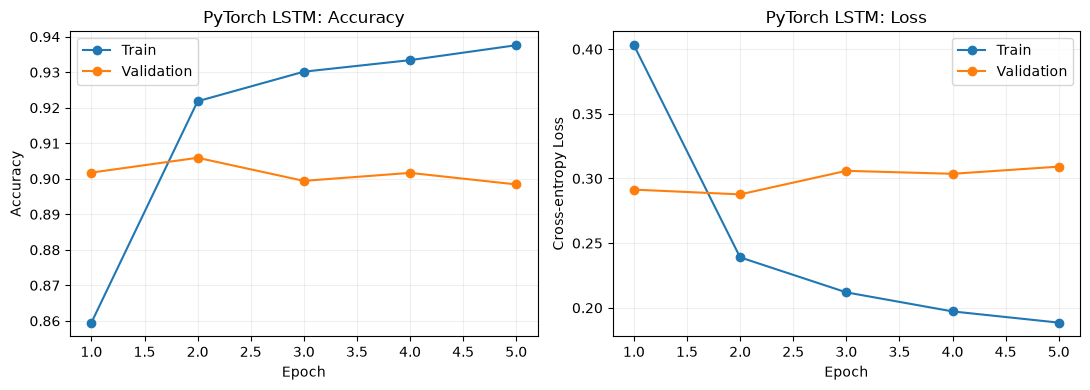

Test Accuracy: 90.11%
Test Loss: 0.3035
Macro-F1: 0.9008
Final Training Time: 1060.5 seconds


In [20]:
if final_model is None:
    print("No final model in memory. Run Step 8 first, or view saved notebook outputs.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(final_history["epoch"], final_history["train_accuracy"], marker="o", label="Train")
    axes[0].plot(final_history["epoch"], final_history["val_accuracy"], marker="o", label="Validation")
    axes[0].set(title="PyTorch LSTM: Accuracy", xlabel="Epoch", ylabel="Accuracy")
    axes[1].plot(final_history["epoch"], final_history["train_loss"], marker="o", label="Train")
    axes[1].plot(final_history["epoch"], final_history["val_loss"], marker="o", label="Validation")
    axes[1].set(title="PyTorch LSTM: Loss", xlabel="Epoch", ylabel="Cross-entropy Loss")
    for ax in axes:
        ax.grid(alpha=0.2)
        ax.legend()
    plt.tight_layout()
    plt.show()

    test_metrics = run_epoch(final_model, test_dl, nn.CrossEntropyLoss())
    print(f"Test Accuracy: {test_metrics['accuracy'] * 100:.2f}%")
    print(f"Test Loss: {test_metrics['loss']:.4f}")
    print(f"Macro-F1: {test_metrics['macro_f1']:.4f}")
    print(f"Final Training Time: {final_info['training_time_s']:.1f} seconds")

## Step 10 — Person 6 Handoff [Person 6: No need to run]

**For Person 6:** This notebook includes saved tables and plots for review. No need to run Step 4B, any Step 5 sweep, Step 7, or Step 8 unless you want to reproduce the experiments. No CSV/PNG/JSON files are saved automatically.

**If you need new results:** Run setup once (Steps 1–4A), the baseline once (Step 4B), then only the selected Step 5 sweep. Step 6 displays completed experiments without training. Step 7 and Step 8 train additional models only when explicitly executed.

**Important:** Re-running a sweep changes the tuning evidence. Rerun optional Step 7 and Step 8 before quoting a new final Test Accuracy. Keep previous completed notebooks if you need earlier results.

**Presentation summary:** Input token IDs → Embedding → LSTM → Dropout → Linear (four logits). Training uses CrossEntropyLoss, Backpropagation, and Adam. Tuning uses one-factor-at-a-time comparisons based on Validation Accuracy.

## Step 11 — Person 5 Results Summary [Run after completed experiments; Person 6: No need to run if saved outputs are visible]

**Purpose:** Display all available Person 5 results together for review and presentation: baseline, four independent hyperparameter sweeps, optional combinations, selected configuration, final training history, and test metrics.

- **No training happens here.** The cell reads results already stored in Python variables by Steps 4–9.
- Run it after your experiments **in the same Jupyter Kernel**. If a section was not run, the summary will identify the missing result.
- For Person 6, open the **saved notebook outputs** to review the results. No need to rerun model training.
- No CSV, JSON, or image files are generated automatically.
- *Important:* Rerunning a sweep invalidates previous final-model results. Complete Steps 7–9 again before reporting new final test metrics.


PERSON 5 — PYTORCH LSTM RESULTS SUMMARY

1. Experiment Setup
Baseline hyperparameters: {'embedding_dim': 64, 'hidden_dim': 64, 'dropout': 0.2, 'learning_rate': 0.001}
Tuning samples: 20000 training / 4000 validation
Tuning epochs per model: 5

2. Baseline Result


,embedding_dim,hidden_dim,dropout,learning_rate,name,best_epoch,Train Accuracy (%),Validation Accuracy (%),train_loss,val_loss,training_time_s
0,64,64,0.2,0.001,Baseline,5,88.76,83.98,0.338,0.4776,51.9103



3. Independent Hyperparameter Tuning

Embedding Dimension (5 tested values)


,embedding_dim,Train Accuracy (%),Validation Accuracy (%),train_loss,val_loss,best_epoch,Training Time (s)
0,16,76.70,76.35,0.5957,0.6103,5,69.2868
1,32,84.47,81.05,0.4474,0.5356,5,46.7231
2,64,88.76,83.98,0.3380,0.4776,5,51.9103
3,128,91.36,85.15,0.2757,0.4783,5,58.3473
4,256,93.98,85.90,0.1996,0.4883,5,72.7215



LSTM Hidden Size (5 tested values)


,hidden_dim,Train Accuracy (%),Validation Accuracy (%),train_loss,val_loss,best_epoch,Training Time (s)
0,16,83.29,78.92,0.5176,0.6121,5,31.3150
1,32,86.27,81.73,0.4203,0.5311,5,34.3874
2,64,88.76,83.98,0.3380,0.4776,5,51.9103
3,128,89.27,84.35,0.3156,0.4713,5,108.1051
4,256,89.70,83.65,0.3104,0.4736,5,223.8703


... (9 outputs left out)

,epoch,train_loss,Train Accuracy (%),val_loss,Validation Accuracy (%),Validation Macro-F1 (%),Accuracy Gap (pp),epoch_train_time_s
0,1,0.4031,85.95,0.2914,90.18,90.16,-4.22,204.2352
1,2,0.2390,92.18,0.2877,90.59,90.55,1.59,172.5326
2,3,0.2119,93.02,0.3059,89.94,89.94,3.07,220.7076
3,4,0.1972,93.34,0.3036,90.17,90.12,3.17,234.2088
4,5,0.1885,93.76,0.3092,89.84,89.84,3.92,228.8157


Best validation epoch: 2
Final model training time: 1060.5 seconds
(Training time excludes validation; not the total tuning time.)

7. Final Test Results


,Test Accuracy (%),Test Loss,Macro-F1,Final Training Time (s)
0,90.11,0.3035,0.9008,1060.5



8. Hyperparameter Trend Plots


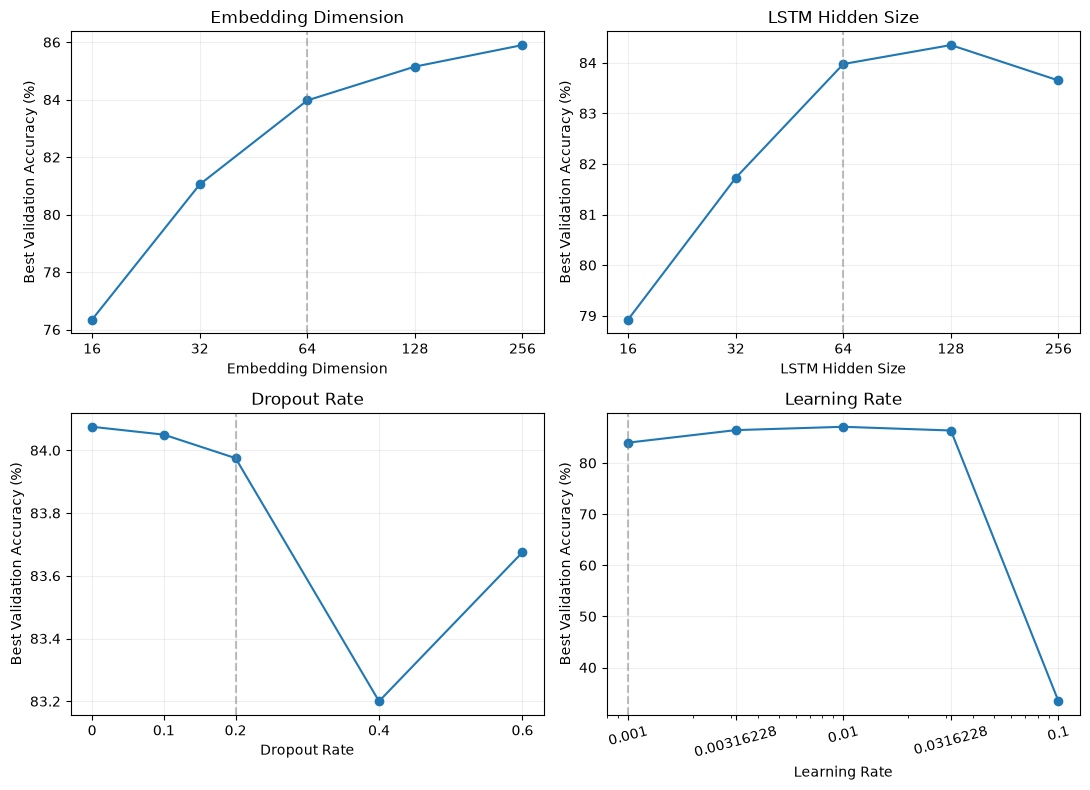


9. Final Training / Validation Learning Curves


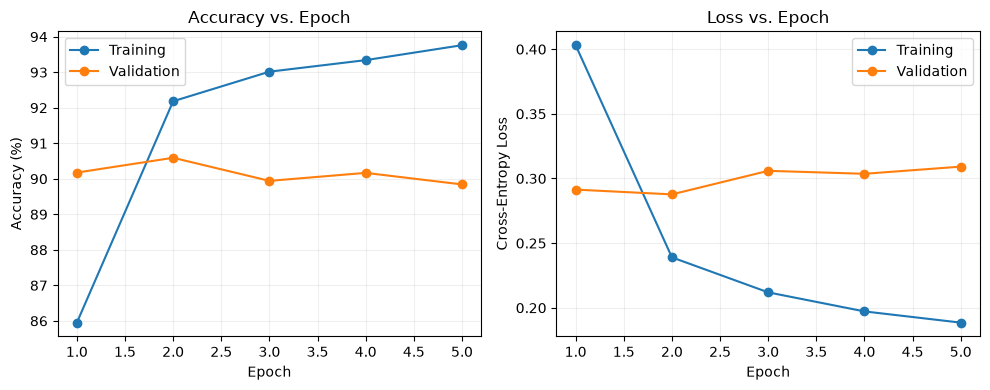

In [21]:
# Show the available Person 5 results in one place (no model training or file export).
print("PERSON 5 — PYTORCH LSTM RESULTS SUMMARY")
print("=" * 48)

# 1. Shared experiment settings and baseline result
if "BASELINE" in globals():
    print("\n1. Experiment Setup")
    print("Baseline hyperparameters:", BASELINE)
    print(f"Tuning samples: {TUNE_TRAIN_SIZE} training / {TUNE_VAL_SIZE} validation")
    print(f"Tuning epochs per model: {TUNE_EPOCHS}")

if "baseline_result" in globals():
    print("\n2. Baseline Result")
    baseline_table = pd.DataFrame([baseline_result]).copy()
    for col in ["train_accuracy", "val_accuracy"]:
        baseline_table[col] = (baseline_table[col] * 100).round(2)
    display(baseline_table.rename(columns={
        "train_accuracy": "Train Accuracy (%)",
        "val_accuracy": "Validation Accuracy (%)"
    }).round(4))
else:
    print("\n2. Baseline Result: Run Step 4B first.")

# 2. Four independent hyperparameter sweeps
print("\n3. Independent Hyperparameter Tuning")
if "sweep_results" in globals() and sweep_results:
    for parameter, label in PARAMETER_LABELS.items():
        if parameter not in sweep_results:
            print(f"\n{label}: not yet run (Step 5).")
            continue
        results = sweep_results[parameter].copy()
        print(f"\n{label} ({len(results)} tested values)")
        cols = [parameter, "train_accuracy", "val_accuracy", "train_loss",
                "val_loss", "best_epoch", "training_time_s"]
        shown = results[cols].copy()
        shown["train_accuracy"] = (shown["train_accuracy"] * 100).round(2)
        shown["val_accuracy"] = (shown["val_accuracy"] * 100).round(2)
        display(shown.rename(columns={
            "train_accuracy": "Train Accuracy (%)",
            "val_accuracy": "Validation Accuracy (%)",
            "training_time_s": "Training Time (s)"
        }).round(4))

    # Combine the completed sweeps without repeating the shared baseline.
    if "baseline_result" in globals():
        all_rows = [baseline_result.copy()]
        for parameter, results in sweep_results.items():
            all_rows.extend(results.loc[results["name"] != "Baseline"].to_dict("records"))
        tested = pd.DataFrame(all_rows)
        tested = tested.sort_values(["val_accuracy", "val_loss"], ascending=[False, True])
        print(f"\nUnique configurations tested (OFAT): {len(tested)}")
        print("Top five OFAT configurations (ranked by validation accuracy):")
        top = tested[["name", "embedding_dim", "hidden_dim", "dropout",
                      "learning_rate", "val_accuracy", "val_loss"]].head(5).copy()
        top["val_accuracy"] = (top["val_accuracy"] * 100).round(2)
        display(top.rename(columns={"val_accuracy": "Validation Accuracy (%)"}).round(5))
else:
    print("No sweep results available yet. Run any Step 5 section to populate them.")

# 3. Optional parameter combinations and the selected final configuration
print("\n4. Combination Experiments")
if "combination_results" in globals() and combination_results is not None:
    combinations = combination_results.copy()
    combinations["val_accuracy"] = (combinations["val_accuracy"] * 100).round(2)
    display(combinations.rename(columns={"val_accuracy": "Validation Accuracy (%)"}).round(5))
else:
    print("Not available (Step 7 is optional).")

print("\n5. Selected Final Configuration")
if "final_model" in globals() and final_model is not None and "best_config" in globals():
    print("Selected from validation results:", best_config)
    if "winning_name" in globals():
        print("Winning tuning experiment:", winning_name)
else:
    print("No current final model. Complete Step 8 to select and train one.")

# 4. Final full-dataset training and test results
print("\n6. Final Training History")
if "final_model" in globals() and final_model is not None and "final_history" in globals():
    history = final_history.copy()
    for col in ["train_accuracy", "val_accuracy", "val_macro_f1", "accuracy_gap"]:
        history[col] = (history[col] * 100).round(2)
    display(history.rename(columns={
        "train_accuracy": "Train Accuracy (%)",
        "val_accuracy": "Validation Accuracy (%)",
        "val_macro_f1": "Validation Macro-F1 (%)",
        "accuracy_gap": "Accuracy Gap (pp)"
    }).round(4))
    print("Best validation epoch:", final_info["best_epoch"])
    print(f"Final model training time: {final_info['training_time_s']:.1f} seconds")
    print("(Training time excludes validation; not the total tuning time.)")
else:
    print("Not available (Step 8 has not produced a current final model).")

print("\n7. Final Test Results")
if ("final_model" in globals() and final_model is not None
        and "test_metrics" in globals() and test_metrics is not None):
    final_summary = pd.DataFrame([{
        "Test Accuracy (%)": round(test_metrics["accuracy"] * 100, 2),
        "Test Loss": round(test_metrics["loss"], 4),
        "Macro-F1": round(test_metrics["macro_f1"], 4),
        "Final Training Time (s)": round(final_info["training_time_s"], 1),
    }])
    display(final_summary)
else:
    print("Not available for the current final model. Complete Step 9 first.")

# 5. Display available charts without retraining anything.
if "sweep_results" in globals() and sweep_results:
    print("\n8. Hyperparameter Trend Plots")
    fig, axes = plt.subplots(2, 2, figsize=(11, 8))
    for ax, (parameter, label) in zip(axes.flat, PARAMETER_LABELS.items()):
        if parameter not in sweep_results:
            ax.set_title(f"{label} (not yet run)")
            ax.axis("off")
            continue
        results = sweep_results[parameter].sort_values(parameter)
        values = results[parameter].tolist()
        ax.plot(values, results["val_accuracy"] * 100, marker="o")
        ax.axvline(BASELINE[parameter], color="gray", linestyle="--", alpha=0.5)
        if parameter in ("embedding_dim", "hidden_dim"):
            ax.set_xscale("log", base=2)
        elif parameter == "learning_rate":
            ax.set_xscale("log")
        ax.set_xticks(values)
        ax.set_xticklabels([f"{v:g}" for v in values], rotation=15 if parameter == "learning_rate" else 0)
        ax.set_title(label)
        ax.set_xlabel(label)
        ax.set_ylabel("Best Validation Accuracy (%)")
        ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

if "final_model" in globals() and final_model is not None and "final_history" in globals():
    print("\n9. Final Training / Validation Learning Curves")
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    for phase in ["train", "val"]:
        axes[0].plot(final_history["epoch"], final_history[f"{phase}_accuracy"] * 100,
                     marker="o", label="Training" if phase == "train" else "Validation")
        axes[1].plot(final_history["epoch"], final_history[f"{phase}_loss"],
                     marker="o", label="Training" if phase == "train" else "Validation")
    axes[0].set(title="Accuracy vs. Epoch", xlabel="Epoch", ylabel="Accuracy (%)")
    axes[1].set(title="Loss vs. Epoch", xlabel="Epoch", ylabel="Cross-Entropy Loss")
    for ax in axes:
        ax.legend()
        ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()


# Notes for Person 6

The PyTorch LSTM implementation, hyperparameter tuning, and final evaluation are included in this notebook.

If the goal is to compare the existing TensorFlow and PyTorch results, the saved outputs can be used directly without retraining.

However, if you want to conduct a controlled comparison using the same model configuration and training conditions, the following cells may need to be reviewed or modified.

## 1. Cells That May Need Modification

| Cell (0-based) | Section | What to Check or Modify |
|---|---|---|
| **5** | Data Loading and Vocabulary | Ensure both frameworks use the same tokenization and vocabulary. |
| **7** | Dataset Preparation | Match `MAX_LEN`, `BATCH_SIZE`, random seed, and train/validation/test split. |
| **12** | LSTM Model Definition | Ensure the same model architecture, including LSTM layers, directions, and dropout placement. |
| **16** | Training Functions | Check the optimizer, loss function, and training/evaluation procedures. |
| **18** | Hyperparameter Setup | Review the `BASELINE` configuration if using the same baseline for comparison. |
| **36** | Final Model Training | This cell automatically selects a configuration from the tuning results. It may need to be replaced with a fixed configuration for a controlled comparison. |
| **38** | Final Evaluation | Use the trained model to obtain test accuracy, loss, Macro-F1, and learning curves. |

The four hyperparameters that should be matched between frameworks are:

- `embedding_dim`
- `hidden_dim`
- `dropout`
- `learning_rate`

Batch size, training epochs, dataset split, and preprocessing should also be consistent.

## 2. Cells to Run for a New Controlled Comparison

**Setup:** Run code Cells **0, 2, 4, 5, 7, 10, 12, and 16** in order to prepare the dataset, define the model, and initialize the training functions.

**Training:** Add a separate training cell after Cell 16 using the agreed configuration. This is simpler than relying on Cell 36, which requires the hyperparameter tuning results.

**Evaluation:** Evaluate the newly trained model on the common validation and test sets, and record its learning curves and performance metrics.

## 3. Sections That Normally Do Not Need to Be Rerun

- **Step 4B:** Shared baseline training
- **Step 5A–5D:** Four independent hyperparameter tuning experiments
- **Step 6:** Tuning summary
- **Step 7:** Optional combination experiments
- **Step 11:** Person 5 results summary, if the saved outputs are available

These sections are mainly for reviewing Person 5's previous experiments. They are not required for a new fixed-configuration framework comparison.

## 4. Important Notes

The two frameworks should use the same actual training and validation samples, not just the same random seed. The PyTorch model also handles padding using packed sequences, so the TensorFlow implementation should use equivalent sequence masking.

For a fair comparison, report validation accuracy, test accuracy, test loss, Macro-F1, and training time. Training time should be measured under comparable hardware and timing conditions.

**The existing Person 5 hyperparameter tuning results can remain unchanged. Only the fixed-configuration training and evaluation need to be rerun if a new controlled comparison is required.**